# Notebook 08: Calibrating the Mike & Farmer (2008) Model

**References:** Mike, S. and Farmer, J. D. (2008). An empirical behavioral model of liquidity and volatility. *Journal of Economic Dynamics and Control*, 32(1), 200–234. Gould et al. (2013), Section 5.2.5.

Mike and Farmer built their model from regularities measured directly in order flow (London Stock Exchange data), not by tuning parameters until the model's output looked right. `MikeFarmer2008Model` has the same structure, and `lob.calibration` estimates each of its parts from an event log by maximum likelihood:

| Part of the model | Parameter | Estimator |
|---|---|---|
| Orders arrive as a Poisson process | `lam` | orders per unit time |
| Price: `round(loc + scale * t_nu)` ticks less aggressive than the same-side best quote | `nu`, `loc`, `scale` | likelihood of the observed integer offsets under the rounded Student's t |
| Order signs: signs of Gaussian FARIMA(0, H − ½, 0) noise | `hurst` | fit of (2/π) arcsin of the FARIMA autocorrelation to the signs' autocorrelation |
| Each resting order canceled at rate $A(1-e^{-y})(s+B)/(1+B)$ | `cancel_rate` $A$, `imbalance_offset` $B$ | likelihood from replaying the log through a book: $A$ in closed form for each $B$, then a one-dimensional maximization |

Here $y$ is an order's distance to the opposite best quote divided by that distance when it was placed, and $s$ the share of resting orders on its side.

The repository has no order-level market data, so this notebook first checks that the estimators recover known parameters from simulated runs, and then sets out what fitting market data would take.

In [1]:
import os
import sys
import warnings
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from joblib import Parallel, delayed

from lob.calibration import (
    calibrate_mf2008, cancellation_statistics, farima_acf, relative_offsets, sample_acf,
    SIGN_LAGS,
)
from lob.models.mike_farmer import MikeFarmer2008Model
from lob.order import reset_order_id_counter
from lob.simulation import Simulation, SimulationConfig
from lob.analysis.plotting import set_style

set_style()
pd.set_option('display.max_colwidth', None)

# The model's defaults, which Notebook 05 uses.
TRUE = dict(lam=1.0, cancel_rate=0.01, imbalance_offset=0.2, hurst=0.75, nu=1.3, loc=1.0, scale=3.0)
SEEDS = list(range(1, 9))
N_STEPS = 150_000  # model steps; the calibration needs the log from an empty book, so no warm-up

N_JOBS = min(8, os.cpu_count() or 1)
warnings.filterwarnings("ignore", message="A worker stopped while some jobs were given to the executor")

## 1. Recovering Known Parameters

Each run simulates the model with the parameters above from an empty book, records every event, and hands the log to `calibrate_mf2008`. Eight seeds show how far the estimates scatter around the truth.

In [2]:
def simulate(seed):
    reset_order_id_counter()
    sim = Simulation(model=MikeFarmer2008Model(initial_mid=10000, **TRUE),
                     config=SimulationConfig(n_events=N_STEPS, warmup_events=0, seed=seed))
    return sim.run(progress=False)


def calibrate(seed):
    log = simulate(seed)
    return calibrate_mf2008(log, initial_mid=10000)


estimates = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(calibrate)(seed) for seed in SEEDS))

rows = {}
for name, true in TRUE.items():
    values = estimates[name]
    half = stats.t.ppf(0.975, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values))
    lo, hi = values.mean() - half, values.mean() + half
    rows[name] = {'true': true, 'mean estimate': round(values.mean(), 4),
                  '95% CI of the mean': f"{lo:.4f} to {hi:.4f}",
                  'spread across seeds (sd)': round(values.std(ddof=1), 4),
                  'covers the truth': 'yes' if lo <= true <= hi else 'no'}
display(pd.DataFrame(rows).T)
print(f"Each run: about {estimates['n_orders'].mean():,.0f} orders and "
      f"{estimates['n_cancels'].mean():,.0f} cancellations.")

,true,mean estimate,95% CI of the mean,spread across seeds (sd),covers the truth
lam,1.0,0.9996,0.9964 to 1.0029,0.0039,yes
cancel_rate,0.01,0.0099,0.0098 to 0.0101,0.0002,yes
imbalance_offset,0.2,0.2065,0.1780 to 0.2349,0.034,yes
hurst,0.75,0.7481,0.7432 to 0.7530,0.0059,yes
nu,1.3,1.3061,1.2940 to 1.3182,0.0145,yes
loc,1.0,0.9981,0.9856 to 1.0106,0.0149,yes
scale,3.0,3.0081,2.9863 to 3.0300,0.0261,yes


Each run: about 68,313 orders and 31,845 cancellations.


In [3]:
missed = [name for name, row in rows.items() if row['covers the truth'] == 'no']
worst = max(TRUE, key=lambda name: abs(estimates[name].mean() / TRUE[name] - 1))
print(f"Largest relative error of a mean estimate: {worst}, "
      f"{abs(estimates[worst].mean() / TRUE[worst] - 1):.1%}.")
if missed:
    print("Means whose 95% interval misses the true value: " + ", ".join(missed) + ".")
else:
    print("Every mean estimate's 95% interval covers the true value: the estimators show no detectable bias.")
noisiest = max(TRUE, key=lambda name: estimates[name].std(ddof=1) / TRUE[name])
print(f"Noisiest relative to its value: {noisiest} (one run's estimate scatters by about "
      f"{estimates[noisiest].std(ddof=1) / TRUE[noisiest]:.0%}).")

Largest relative error of a mean estimate: imbalance_offset, 3.2%.
Every mean estimate's 95% interval covers the true value: the estimators show no detectable bias.
Noisiest relative to its value: imbalance_offset (one run's estimate scatters by about 17%).


## 2. What Each Estimator Sees

One run, three diagnostics: the price offsets against the fitted rounded Student's t; the order signs' autocorrelation against the fitted long-memory curve; and the likelihood of the cancellation parameter $B$ (with $A$ at its best value for each $B$).

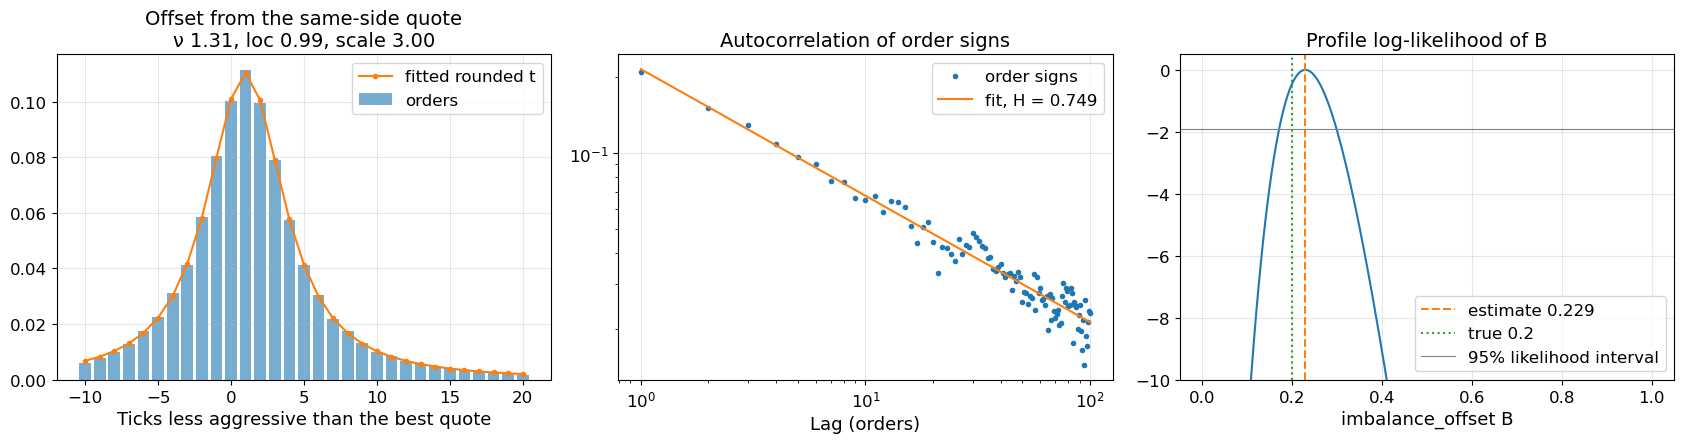

95% likelihood interval for B from this one run: 0.175 to 0.295 (true 0.2).


In [4]:
log = simulate(SEEDS[0])
est = estimates.iloc[0]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

offsets = relative_offsets(log)
values, counts = np.unique(offsets, return_counts=True)
window = (values >= -10) & (values <= 20)
pmf = (stats.t.cdf((values + 0.5 - est['loc']) / est['scale'], est['nu'])
       - stats.t.cdf((values - 0.5 - est['loc']) / est['scale'], est['nu']))
axes[0].bar(values[window], counts[window] / counts.sum(), color='C0', alpha=0.6, label='orders')
axes[0].plot(values[window], pmf[window], 'o-', color='C1', markersize=3, label='fitted rounded t')
axes[0].set_title(f"Offset from the same-side quote\nν {est['nu']:.2f}, loc {est['loc']:.2f}, scale {est['scale']:.2f}")
axes[0].set_xlabel('Ticks less aggressive than the best quote')
axes[0].legend()

signs = np.where(log.loc[log['event_type'] != 'cancel', 'side'] == 'bid', 1.0, -1.0)
lags = np.arange(1, SIGN_LAGS + 1)
axes[1].loglog(lags, sample_acf(signs, SIGN_LAGS), '.', label='order signs')
axes[1].loglog(lags, 2 / np.pi * np.arcsin(farima_acf(est['hurst'] - 0.5, SIGN_LAGS)), color='C1',
               label=f"fit, H = {est['hurst']:.3f}")
axes[1].set_title('Autocorrelation of order signs')
axes[1].set_xlabel('Lag (orders)')
axes[1].legend()

cancel_stats = cancellation_statistics(log, initial_mid=10000)
n = len(cancel_stats['share'])
b_grid = np.linspace(0.0, 1.0, 201)
profile = [np.log(cancel_stats['share'] + b).sum() - n * np.log(cancel_stats['w_u'] + b * cancel_stats['w_v'])
           for b in b_grid]
profile = np.array(profile) - max(profile)
axes[2].plot(b_grid, profile)
axes[2].axvline(est['imbalance_offset'], color='C1', linestyle='--', label=f"estimate {est['imbalance_offset']:.3f}")
axes[2].axvline(TRUE['imbalance_offset'], color='C2', linestyle=':', label=f"true {TRUE['imbalance_offset']}")
axes[2].axhline(-1.92, color='grey', linewidth=0.8, label='95% likelihood interval')
axes[2].set_ylim(-10, 0.5)
axes[2].set_title('Profile log-likelihood of B')
axes[2].set_xlabel('imbalance_offset B')
axes[2].legend()
plt.tight_layout()
plt.show()

inside = b_grid[profile >= -1.92]
print(f"95% likelihood interval for B from this one run: {inside.min():.3f} to {inside.max():.3f} "
      f"(true {TRUE['imbalance_offset']}).")

## 3. Fitting Market Data in LOBSTER's Format

Order-level market data such as LOBSTER's (Nasdaq's book, reconstructed from its ITCH messages) carries what the estimators need, in a form that `lob/lobster.py` converts:

- **New orders** (type 1) arrive with their price (dollars × 10,000; here in ticks of a cent).
- **Executions** (types 4 and 5) show an aggressive order only through the resting orders it hit: its sign is the opposite of theirs and its size the sum of its executions at one time. If part of it rests, a new-order message follows at the same time with its price. If it executed in full, its own limit price is never recorded, only that it was at least as aggressive as the worst price it traded at, so the price fit treats its offset as **censored** at that bound (exact for this model: with one order size, the fills depend on the price only through that bound).
- **Cancellations**: full ones (type 3) are the model's; partial ones (type 2), which the model lacks, only shrink an order by default.
- A day's file starts with **a book full of orders placed before it**, whose placement is unknown: the cancellation replay follows only the orders it sees placed and counts after a burn-in.

`simulated_lobster` writes the model's own runs in this format, hiding what Nasdaq's feed hides, so the path from files to estimates can be checked against known parameters before it meets real data.

In [5]:
import tempfile
from pathlib import Path

from lob.calibration import fit_rounded_t
from lob.lobster import (
    calibrate_lobster, lobster_orders, order_offsets, read_lobster, save_lobster, simulated_lobster,
)


def lobster_run(seed, skip_events=0):
    reset_order_id_counter()
    return simulated_lobster(lambda: MikeFarmer2008Model(initial_mid=10000, **TRUE), N_STEPS, seed=seed,
                             skip_events=skip_events)


# One run written as LOBSTER's two files and read back.
messages, book = lobster_run(SEEDS[0])
with tempfile.TemporaryDirectory() as folder:
    files = save_lobster(messages, book, folder)
    messages, book = read_lobster(*files)
print("Files:", ", ".join(f.name for f in files))
print(f"{len(messages):,} messages, and the book after each to {book.shape[1] // 4} levels. The first messages:")
messages.head(8)

Files: SIM_2012-06-21_34200000_57600000_message_10.csv, SIM_2012-06-21_34200000_57600000_orderbook_10.csv
150,000 messages, and the book after each to 10 levels. The first messages:


,time,type,order_id,size,price,direction
0,34201.073029,1,1,1,1000100,1
1,34201.327944,1,2,1,1001100,-1
2,34201.446148,1,3,1,999900,1
3,34203.265167,1,4,1,998900,1
4,34204.196110,1,5,1,1001500,-1
5,34205.590131,1,6,1,1002000,-1
6,34207.319810,1,7,1,1001500,-1
7,34207.709568,1,8,1,1000900,-1


In [6]:
def lobster_estimates(seed):
    messages, book = lobster_run(seed)
    exact, _ = order_offsets(lobster_orders(messages, book))
    return calibrate_lobster(messages, book), fit_rounded_t(exact)  # the second: only the prices that show


pairs = Parallel(n_jobs=N_JOBS)(delayed(lobster_estimates)(seed) for seed in SEEDS)
from_files = pd.DataFrame([p[0] for p in pairs])
naive = pd.DataFrame([p[1] for p in pairs])


def interval(values):
    half = stats.t.ppf(0.975, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values))
    return values.mean() - half, values.mean() + half


file_rows = {}
for name, true in TRUE.items():
    lo, hi = interval(from_files[name])
    row = {'true': true, 'mean estimate': from_files[name].mean(), '95% interval': f"{lo:.3g} to {hi:.3g}",
           'covers the truth': 'yes' if lo <= true <= hi else 'no'}
    if name in naive:
        nlo, nhi = interval(naive[name])
        row['fitting only the prices that show'] = f"{naive[name].mean():.3g} ({nlo:.3g} to {nhi:.3g})"
    file_rows[name] = row
share = (from_files['n_executed_in_full'] / from_files['n_orders']).mean()
print(f"Orders that executed in full, whose price the files do not show: {share:.0%} of all orders.")
pd.DataFrame(file_rows).T.fillna('')

Orders that executed in full, whose price the files do not show: 27% of all orders.


,true,mean estimate,95% interval,covers the truth,fitting only the prices that show
lam,1.0,0.999996,0.997 to 1,yes,
cancel_rate,0.01,0.009971,0.00986 to 0.0101,yes,
imbalance_offset,0.2,0.202524,0.179 to 0.226,yes,
hurst,0.75,0.748715,0.744 to 0.753,yes,
nu,1.3,1.305002,1.3 to 1.31,yes,1.39 (1.38 to 1.39)
loc,1.0,1.000879,0.991 to 1.01,yes,1.99 (1.98 to 1.99)
scale,3.0,3.003994,2.99 to 3.02,yes,2.1 (2.09 to 2.11)


In [7]:
missed = [name for name, row in file_rows.items() if row['covers the truth'] == 'no']
print("From the files, " + ("every mean estimate's 95% interval covers the true value."
                            if not missed else "these means' 95% intervals miss the true value: "
                            + ", ".join(missed) + "."))
error = {name: naive[name].mean() / TRUE[name] - 1 for name in naive}
worst = max(error, key=lambda name: abs(error[name]))
print(f"Fitting only the prices that show would get {worst} wrong by {error[worst]:+.0%}: the orders that "
      "executed in full are the most aggressive, so leaving them out pulls the fit toward passive orders.")

From the files, every mean estimate's 95% interval covers the true value.
Fitting only the prices that show would get loc wrong by +99%: the orders that executed in full are the most aggressive, so leaving them out pulls the fit toward passive orders.


### A file that starts on a full book

Here each run is written only after its first 50,000 events, so the file begins, as a real day's does, with a book of orders it never shows being placed. The replay leaves those out; `last_unknown` reports when the last of them traded or left, and a burn-in that long leaves them out of the counts entirely.

In [8]:
def full_book(seed):
    messages, book = lobster_run(seed + 100, skip_events=50_000)
    early = calibrate_lobster(messages, book)
    late = calibrate_lobster(messages, book, burn_in=early['last_unknown'] + 1)
    return early, late, messages['time'].iloc[-1] - messages['time'].iloc[0]


runs = Parallel(n_jobs=N_JOBS)(delayed(full_book)(seed) for seed in SEEDS)
early = pd.DataFrame([r[0] for r in runs])
late = pd.DataFrame([r[1] for r in runs])
span = np.mean([r[2] for r in runs])
for name in ('cancel_rate', 'imbalance_offset'):
    lo, hi = interval(early[name])
    print(f"{name}: true {TRUE[name]}; without a burn-in {early[name].mean():.4g} ({lo:.4g} to {hi:.4g}), "
          f"with one {late[name].mean():.4g}")
print(f"The orders placed before the file were gone after {early['last_unknown'].mean():,.0f} of its "
      f"{span:,.0f} time units; without a burn-in, {early['n_cancels_skipped'].mean():.0f} of their "
      f"cancellations are left out of each run, against {early['n_cancels'].mean():,.0f} counted.")

cancel_rate: true 0.01; without a burn-in 0.009958 (0.009879 to 0.01004), with one 0.009955
imbalance_offset: true 0.2; without a burn-in 0.205 (0.1896 to 0.2205), with one 0.2049
The orders placed before the file were gone after 1,210 of its 102,260 time units; without a burn-in, 100 of their cancellations are left out of each run, against 47,756 counted.


### Real data

To fit a real stock, request LOBSTER's free sample files on lobsterdata.com (the form asks for an email address) and unzip them into `data/lobster/` in this repository, which git ignores; the next cell fits every message file it finds there, with ticks of a cent and a 30-minute burn-in. `lam` is then in orders per second.

Real data also depart from the model in ways the estimates absorb: order sizes vary (the model has one; `lot_size` is the most common), hidden orders trade without being seen (`n_hidden_executions`), partial cancellations shrink orders (`n_partial_cancels`), and arrival rates change through the day (the estimate is their average). Mike and Farmer dealt with such issues for their London stocks; the estimators here have been checked on the model's own runs in LOBSTER's format, as above.

In [9]:
DATA = Path('..') / 'data' / 'lobster'
message_files = sorted(DATA.glob('*_message_*.csv'))
if not message_files:
    print(f"No LOBSTER files in {DATA.resolve()}: put the free sample files there to fit them.")
for message_file in message_files:
    orderbook_file = message_file.with_name(message_file.name.replace('_message_', '_orderbook_'))
    real_messages, real_book = read_lobster(message_file, orderbook_file)
    fit = calibrate_lobster(real_messages, real_book, burn_in=1_800)
    print(message_file.name)
    print("  " + ", ".join(f"{key} {value:.4g}" if isinstance(value, float) else f"{key} {value}"
                           for key, value in fit.items()))

No LOBSTER files in /Users/mengren/Documents/new_projects/limit_order_book_simulation/data/lobster: put the free sample files there to fit them.
